# Agente inversor: resultados en el período held-out

Evaluación final del agente congelado en la parte 12 (DQN, recompensa v1,
3 semillas) sobre el período de **test, 2016-01-04 → 2018-08-29**, que no se
usó para ninguna decisión. Se ejecuta una sola vez, con el procedimiento
fijado en las partes 12 y 13: `evaluation.compare` verifica los hashes de los
modelos antes de evaluarlos.

23. Curva de capital del agente frente a los baselines
24–26. Retorno acumulado, máximo drawdown y costos
27. Evolución de las posiciones del agente
28. Comparación entre las versiones de la recompensa
29. Comportamientos inesperados del agente

In [1]:
import os
from pathlib import Path

# Ejecutar desde la raíz del repositorio, como la CLI.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
from stable_baselines3 import DQN

from rl_games_sb import backtest, evaluation, investor

PERIOD = "test"

runs = evaluation.compare(PERIOD)  # verifica los hashes del agente congelado
metrics = evaluation.per_run(runs)
table = evaluation.summary(metrics)

agent_days = dict(enumerate(runs[evaluation.AGENT]))  # semilla -> filas diarias
bh_days = runs[evaluation.BUY_AND_HOLD][0]
prices = investor.load()["close"].reindex(bh_days.index)
asset_return = prices.pct_change().shift(-1)  # retorno del día t al t+1, el que gana la decisión de t
print(f"{PERIOD}: {bh_days.index[0].date()} → {bh_days.index[-1].date()}, {len(bh_days) - 1} decisiones")

test: 2016-01-04 → 2018-08-29, 669 decisiones


## 23. Curva de capital del agente frente a los baselines

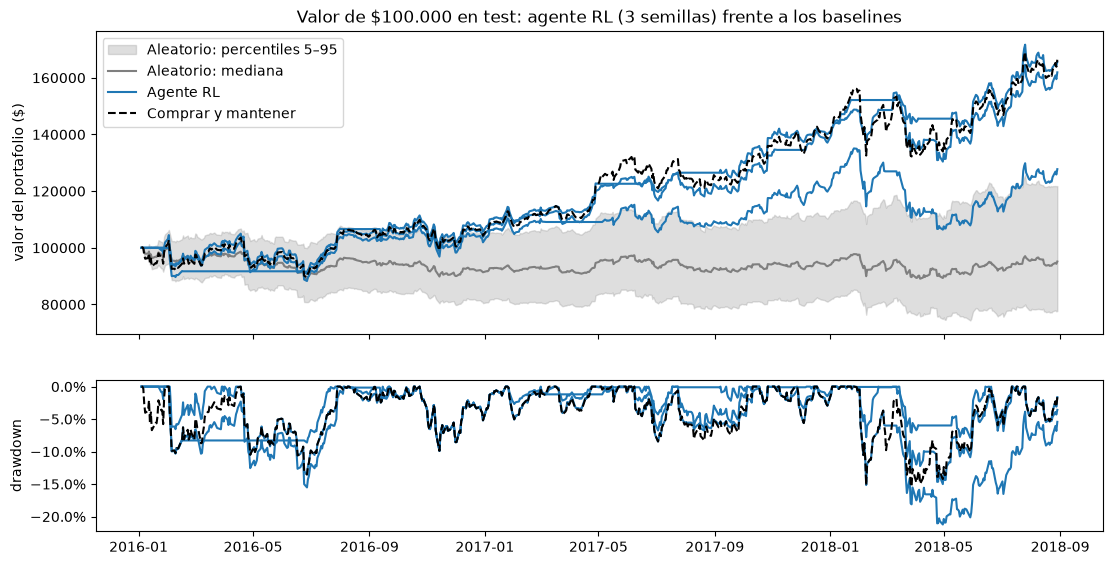

In [2]:
evaluation.plot_equity(runs, f"Valor de $100.000 en {PERIOD}: agente RL (3 semillas) frente a los baselines")

**Interpretación:** en test el agente **no supera a comprar y mantener**.
Dos semillas terminan cerca (+65,5 % y +61,9 %, contra +66,4 %) y la tercera
muy por debajo (+27,8 %). Las tres quedan muy por encima de la banda del
agente aleatorio, que en su mediana pierde dinero. Los tramos planos de las
curvas son los períodos fuera del mercado. Algunos evitaron caídas (la semilla 0
salió entre julio y septiembre de 2017 y redujo su posición en marzo de 2018)
y otros dejaron pasar subidas (la semilla 2 estuvo en efectivo de marzo a mayo
de 2017, mientras el activo subía 12 %). En la curva de drawdown, la semilla 0
cae menos que comprar y mantener en la corrección de febrero a abril de 2018
(−8 % contra −15 %), pero la semilla 2 cae más (−21 %).

## 24–26. Retorno acumulado, máximo drawdown y costos

In [3]:
report = pd.DataFrame({
    "Retorno acumulado": table["total_return"],
    "Máximo drawdown": table["max_drawdown"],
    "Costos": table["costs"],
    "Costos (% del capital inicial)": table["costs"] / investor.INITIAL_CAPITAL,
}).rename_axis("Estrategia")
report.style.format({
    "Retorno acumulado": "{:+.1%}",
    "Máximo drawdown": "{:+.1%}",
    "Costos": "${:,.0f}",
    "Costos (% del capital inicial)": "{:.2%}",
})

,Retorno acumulado,Máximo drawdown,Costos,Costos (% del capital inicial)
Estrategia,,,,
Agente RL,+51.7%,-15.5%,"$1,611",1.61%
Comprar y mantener,+66.4%,-15.4%,$100,0.10%
Aleatorio,-4.8%,-18.5%,"$28,216",28.22%


In [4]:
LABELS = {
    "total_return": "retorno acumulado", "annual_return": "retorno anual", "volatility": "volatilidad anual",
    "sharpe": "Sharpe", "max_drawdown": "máximo drawdown", "trades": "operaciones", "costs": "costos ($)",
    "exposure": "exposición media",
}
FORMATS = {
    "retorno acumulado": "{:+.1%}", "retorno anual": "{:+.1%}", "volatilidad anual": "{:.1%}",
    "Sharpe": "{:.2f}", "máximo drawdown": "{:+.1%}", "operaciones": "{:.0f}", "costos ($)": "{:,.0f}",
    "exposición media": "{:.2f}",
}
random_metrics = metrics.loc[evaluation.RANDOM]
detail = pd.concat([
    metrics.loc[evaluation.AGENT].rename(index=lambda i: f"{evaluation.AGENT}, semilla {i}"),
    table.loc[[evaluation.AGENT]].rename(index={evaluation.AGENT: f"{evaluation.AGENT}, media"}),
    metrics.loc[evaluation.BUY_AND_HOLD].rename(index=lambda i: evaluation.BUY_AND_HOLD),
    random_metrics.quantile([0.05, 0.5, 0.95]).rename(index=lambda q: f"{evaluation.RANDOM}, percentil {q:.0%}"),
]).drop(columns="final_value").rename(columns=LABELS)
detail.style.format(FORMATS)

,retorno acumulado,retorno anual,volatilidad anual,Sharpe,máximo drawdown,operaciones,costos ($),exposición media
"Agente RL, semilla 0",+65.5%,+20.9%,13.3%,1.49,-10.3%,22,"1,854",0.59
"Agente RL, semilla 1",+61.9%,+19.9%,16.6%,1.18,-15.0%,18,"1,651",0.76
"Agente RL, semilla 2",+27.8%,+9.7%,17.9%,0.60,-21.2%,19,"1,327",0.83
"Agente RL, media",+51.7%,+16.8%,16.0%,1.09,-15.5%,20,"1,611",0.72
Comprar y mantener,+66.4%,+21.1%,20.1%,1.06,-15.4%,1,100,1.00
"Aleatorio, percentil 5%",-22.3%,-9.1%,12.0%,-0.62,-27.6%,429,"24,626",0.47
"Aleatorio, percentil 50%",-4.8%,-1.9%,12.9%,-0.08,-18.5%,448,"28,216",0.50
"Aleatorio, percentil 95%",+21.8%,+7.7%,13.9%,0.65,-11.4%,468,"31,704",0.53


In [5]:
# ¿En qué percentil del agente aleatorio queda cada semilla? (mayor es mejor en las tres métricas)
rank = pd.DataFrame({
    seed: {
        "retorno acumulado": (random_metrics["total_return"] < m["total_return"]).mean(),
        "máximo drawdown": (random_metrics["max_drawdown"] < m["max_drawdown"]).mean(),
        "Sharpe": (random_metrics["sharpe"] < m["sharpe"]).mean(),
    }
    for seed, m in metrics.loc[evaluation.AGENT].iterrows()
}).T.rename_axis("semilla")
print("Fracción de los 200 agentes aleatorios que cada semilla supera:")
rank.style.format("{:.0%}")

Fracción de los 200 agentes aleatorios que cada semilla supera:


,retorno acumulado,máximo drawdown,Sharpe
semilla,,,
0,100%,98%,100%
1,100%,73%,100%
2,98%,34%,94%


**Interpretación:**

- **Retorno acumulado:** el agente gana en promedio +51,7 %, unos 15 puntos
  menos que comprar y mantener (+66,4 %). La ventaja que mostró en validación
  (+56 % contra +47 %) no se sostuvo, como se advirtió en la parte 9: κ se
  eligió mirando validación, y ese resultado era optimista.
- **Máximo drawdown:** en promedio es igual (−15,5 % contra −15,4 %), pero varía
  mucho entre semillas: −10 %, −15 % y −21 %.
- **Riesgo ajustado:** al estar invertido en promedio un 72 % del tiempo, el
  agente tiene menos volatilidad (16,0 % contra 20,1 %), y su Sharpe medio es
  prácticamente el mismo (1,09 contra 1,06). Pierde retorno a cambio de menos
  oscilación, en una proporción parecida a la que se lograría manteniendo una
  exposición fija menor.
- **Costos:** 20 operaciones en 2,7 años cuestan $1.611 (1,6 % del capital
  inicial). El agente aleatorio paga $28.216 (28 % del capital) y por eso pierde
  dinero en un mercado que subió 66 %.
- **Frente al azar:** cada semilla supera al 98–100 % de los agentes aleatorios
  en retorno y al 94–100 % en Sharpe. Lo que el agente aprendió de forma
  robusta es la disciplina de operar poco y estar invertido la mayor parte del
  tiempo.

## 27. Evolución de las posiciones del agente

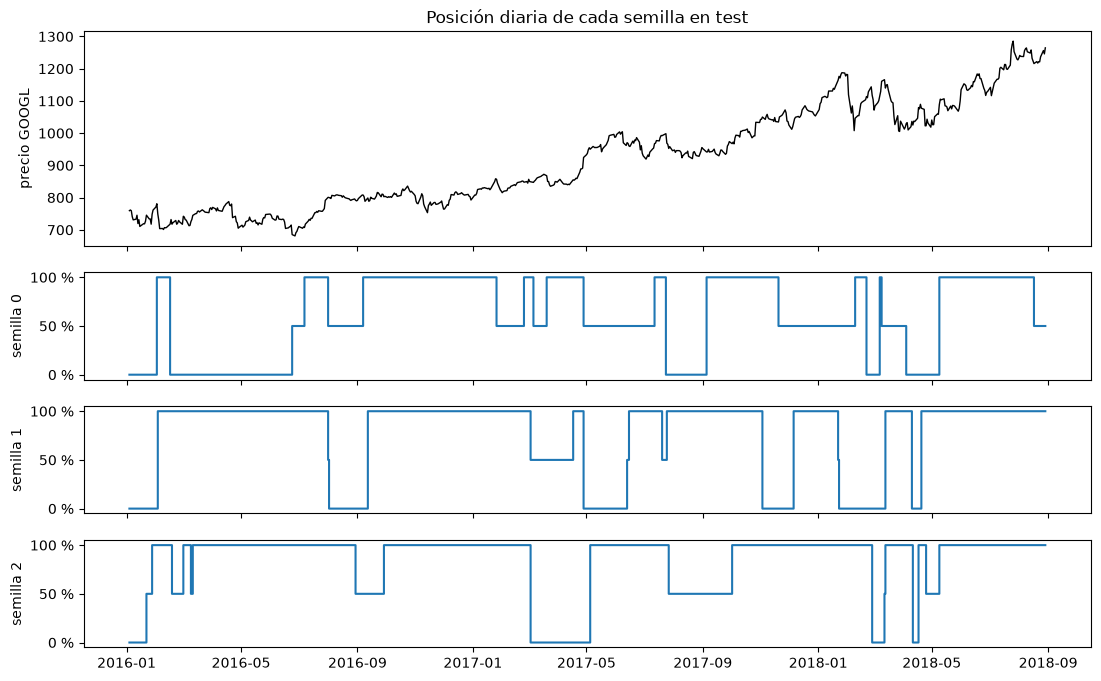

,días en 0 %,días en 50 %,días en 100 %,operaciones,días por tramo (mediana)
semilla,,,,,
0,26%,29%,44%,22,20
1,21%,6%,73%,18,24
2,10%,14%,76%,19,14


In [6]:
fig, axes = plt.subplots(len(agent_days) + 1, 1, figsize=(13, 8), sharex=True,
                         height_ratios=[2] + [1] * len(agent_days))
axes[0].plot(prices, color="black", lw=1)
axes[0].set_ylabel("precio GOOGL")
axes[0].set_title(f"Posición diaria de cada semilla en {PERIOD}")
for ax, (seed, days) in zip(axes[1:], agent_days.items()):
    ax.step(days.index, days["position"], where="post", color="tab:blue")
    ax.set_yticks([0, 0.5, 1], ["0 %", "50 %", "100 %"])
    ax.set_ylabel(f"semilla {seed}")
plt.show()


def stretches(days):
    # Tramos consecutivos con la misma posición objetivo.
    pos = days["position"].dropna()
    groups = (pos != pos.shift()).cumsum()
    return pd.DataFrame([
        {"desde": g.index[0].date(), "hasta": g.index[-1].date(), "días": len(g), "posición": g.iloc[0],
         "retorno del activo en el tramo": (asset_return.loc[g.index] + 1).prod() - 1}
        for _, g in pos.groupby(groups)
    ])


positions = pd.DataFrame({
    seed: {
        "días en 0 %": (d["position"] == 0).mean(),
        "días en 50 %": (d["position"] == 0.5).mean(),
        "días en 100 %": (d["position"] == 1).mean(),
        "operaciones": backtest.metrics(d)["trades"],
        "días por tramo (mediana)": stretches(d)["días"].median(),
    }
    for seed, d in agent_days.items()
}).T.rename_axis("semilla")
positions.style.format({"días en 0 %": "{:.0%}", "días en 50 %": "{:.0%}", "días en 100 %": "{:.0%}",
                        "operaciones": "{:.0f}", "días por tramo (mediana)": "{:.0f}"})

**¿Las salidas del mercado aportaron?** Para cada tramo en que una semilla
estuvo por debajo del 100 %, se compara con lo que hizo el activo durante ese
tramo. Si el activo bajó, la salida evitó una pérdida; si subió, la salida
dejó de ganar. El efecto de cada tramo frente a comprar y mantener es
aproximadamente −(1 − posición) × retorno del activo.

In [7]:
exit_rows = []
for seed, d in agent_days.items():
    s = stretches(d)
    for _, row in s[s["posición"] < 1].iterrows():
        exit_rows.append({"semilla": seed, **row,
                          "efecto frente a comprar y mantener": -(1 - row["posición"]) * row["retorno del activo en el tramo"]})
exits = pd.DataFrame(exit_rows)
print("Efecto total de los tramos fuera del 100 %, por semilla (suma aproximada):")
print(exits.groupby("semilla")["efecto frente a comprar y mantener"].sum().map("{:+.1%}".format).to_string())
exits.sort_values("efecto frente a comprar y mantener").style.format({
    "posición": "{:.0%}", "retorno del activo en el tramo": "{:+.1%}", "efecto frente a comprar y mantener": "{:+.1%}",
}).hide(axis="index")

Efecto total de los tramos fuera del 100 %, por semilla (suma aproximada):
semilla
0     -0.5%
1     -1.8%
2    -26.5%


semilla,desde,hasta,días,posición,retorno del activo en el tramo,efecto frente a comprar y mantener
2,2017-03-03,2017-05-04,44,0%,+11.9%,-11.9%
0,2018-04-04,2018-05-08,25,0%,+5.8%,-5.8%
2,2018-04-11,2018-04-16,4,0%,+5.3%,-5.3%
1,2017-04-28,2017-06-12,31,0%,+5.0%,-5.0%
2,2018-02-27,2018-03-09,9,0%,+4.3%,-4.3%
1,2018-04-10,2018-04-19,8,0%,+3.9%,-3.9%
2,2018-04-25,2018-05-08,10,50%,+6.4%,-3.2%
0,2016-01-04,2016-02-01,20,0%,+2.8%,-2.8%
0,2017-04-28,2017-07-11,51,50%,+4.7%,-2.3%
0,2018-08-17,2018-08-28,8,50%,+4.0%,-2.0%


**Interpretación:** el agente mantiene cada posición durante semanas (la
mediana de sus tramos va de 14 a 24 días, según la semilla) y está al 100 % entre el 44 % y el
76 % de los días. Las semillas se comportan distinto: la 0 usa mucho el 50 %
(29 % de los días), mientras las otras dos casi no lo usan.

La tabla de tramos responde si sus salidas del mercado aportaron. Sumando el
efecto de cada tramo frente a comprar y mantener, el resultado es −0,5 %,
−1,8 % y −26,5 %. **Las salidas no agregaron retorno:** las que evitaron caídas
(por ejemplo, −5,7 % evitado en julio–septiembre de 2017 por la semilla 0) se
compensaron con las que dejaron pasar subidas (+11,9 % perdido por la semilla 2
en marzo–mayo de 2017). En test, el agente no supo anticipar cuándo salir.

## 28. Comparación entre las versiones de la recompensa

La recompensa v1 se eligió en la parte 9 con validación. Aquí se agrega cómo
se comportan v0 y v1 en test. v0 no es el agente final: su resultado en test
se reporta solo para completar la comparación y no cambia ninguna decisión.

In [8]:
versions = {"v0: log-retorno": ("investor-v0", "investor-v0"),
            "v1: log-retorno − 400 bps por operar": ("investor-pen400", "investor-penalized-v0")}
version_rows = []
for name, (save, env_id) in versions.items():
    for seed in range(3):
        model = DQN.load(f"saves/dqn_{save}_seed{seed}.zip", device="cpu")
        for p in ["train", "valid", PERIOD]:
            d = backtest.run(lambda obs, m=model: m.predict(obs, deterministic=True)[0], p, env_id)
            version_rows.append({"recompensa": name, "período": p, "semilla": seed, **backtest.metrics(d)})
versions_table = (pd.DataFrame(version_rows).drop(columns=["semilla", "final_value"])
                  .groupby(["recompensa", "período"], sort=False).mean().rename(columns=LABELS))
print("Media de 3 semillas por recompensa y período")
versions_table.style.format(FORMATS)

Media de 3 semillas por recompensa y período


**Interpretación:** la comparación entre recompensas se sostiene en test.
v0 gana +4,9 % con 283 operaciones y $20.429 en costos: su resultado en train
(+2.250 %) era memorización, y en datos nuevos opera mucho y casi no gana.
v1 gana +51,7 % con 20 operaciones. La penalización por operar fue la decisión
de diseño con más efecto en todo el proyecto.

v1 también muestra algo de sobreajuste: rinde +32 % anual en train y +17 %
anual en test.

## 29. Comportamientos inesperados del agente

In [9]:
# a) ¿Las 3 semillas coinciden? Días en que una está en 0 % y otra en 100 %.
positions_by_seed = pd.DataFrame({seed: d["position"] for seed, d in agent_days.items()}).dropna()
opposite = (positions_by_seed.max(axis=1) - positions_by_seed.min(axis=1)) == 1
print(f"Días en que las semillas toman posiciones opuestas (0 % y 100 %): {opposite.mean():.0%}")

# b) Los movimientos más grandes del período: ¿qué posición tenía cada semilla?
big = asset_return.dropna().abs().nlargest(8).index
moves = positions_by_seed.loc[big].assign(**{"retorno del activo": asset_return.loc[big]})
moves.index = [f"{d.date()} → siguiente cierre" for d in big]
moves.style.format({"retorno del activo": "{:+.1%}"} | {s: "{:.0%}" for s in agent_days})

Días en que las semillas toman posiciones opuestas (0 % y 100 %): 41%


,0,1,2,retorno del activo
2016-04-21 → siguiente cierre,0%,100%,100%,-5.4%
2018-02-01 → siguiente cierre,50%,0%,100%,-5.3%
2018-02-02 → siguiente cierre,50%,0%,100%,-5.1%
2018-04-23 → siguiente cierre,0%,100%,100%,-4.8%
2018-02-07 → siguiente cierre,50%,0%,100%,-4.5%
2018-03-26 → siguiente cierre,50%,100%,100%,-4.5%
2016-01-27 → siguiente cierre,0%,0%,50%,+4.3%
2017-10-26 → siguiente cierre,100%,100%,100%,+4.3%


**Comportamiento inesperado ya documentado (parte 9):** con la recompensa v0
el agente hizo *reward hacking*: memorizó el camino de precios de train
(+2.250 % en train contra +7 % en validación), y un ruido de 0,1 desviaciones
en sus observaciones le quitaba más de la mitad de su resultado en train.

**Lo que muestra el test: las semillas no se ponen de acuerdo.** En el 41 % de
los días una semilla está en 0 % y otra en 100 % (en validación era el 24 %).
Las tres se entrenaron con los mismos datos, la misma recompensa y los mismos
hiperparámetros, y solo difieren en la inicialización aleatoria. En los días de
mayor movimiento las decisiones parecen al azar. En la caída de febrero de 2018
(−5,3 %, −5,1 % y −4,5 % en tres sesiones entre el 2 y el 8 de febrero) la semilla 0 estaba al 50 %, la 1 en
efectivo y la 2 al 100 %. En la caída del 22 de abril de 2016 (−5,4 %), la
semilla 0 estaba fuera y las otras dos dentro.

**Interpretación:** lo que se repite en las tres semillas es operar poco y
estar invertido la mayor parte del tiempo. **El momento de entrar y salir es
distinto en cada una**, lo que indica que la señal de timing que aprendió cada
red es en buena parte ruido de su inicialización y no una regla del mercado.
Es coherente con el análisis exploratorio: los indicadores no anticipan la
dirección del precio del día siguiente.